# Fine-tune on PanopTILs Refined

Adapt a pretrained model to find nuclei and cell types in PanopTILs images.
First run [Prepare PanopTILs](prepare-data.ipynb) to create the images and labels.

Start by training the segmentation layers, then adjust the whole model.


## Setup

In [1]:
import json
import random
from pathlib import Path

import albumentations as A
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from huggingface_hub import hf_hub_download
from matplotlib.patches import Patch
from skimage.color import label2rgb
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader

from cellseg_models_pytorch.inference.post_processor import PostProcessor
from cellseg_models_pytorch.losses import CELoss, DiceLoss, JointLoss, MSE, MultiTaskLoss
from cellseg_models_pytorch.metrics import panoptic_quality
from cellseg_models_pytorch.models.cellpose import CellPose
from cellseg_models_pytorch.transforms.albu_transforms import (
    AlbuStrongAugment, ApplyEach, CellposeTransform, MinMaxNormalization,
)
from cellseg_models_pytorch.transforms.functional.normalization import minmax_normalize
from cellseg_models_pytorch.torch_datasets import TrainDatasetFolder
from cellseg_models_pytorch.utils import FileHandler

seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
data_root = Path("../../data/panoptils-nuclei")
class_names = [
    "background", "neoplastic", "stromal", "inflammatory",
    "epithelial", "other", "unknown",
]
print(f"Device: {device}")


Device: cuda


## Load images and labels

Pair each image with its nucleus and cell-type labels. Scale image pixels to 0–1.
For training, flip images and labels together and vary the image colours.
Validation images are scaled without random changes.


In [2]:
train_transforms = A.Compose([
    A.HorizontalFlip(p=0.33),
    A.VerticalFlip(p=0.33),
    AlbuStrongAugment(seed=seed),
    MinMaxNormalization(copy=True),
], seed=seed)
validation_transforms = A.Compose([MinMaxNormalization(copy=True)])
instance_transforms = ApplyEach([CellposeTransform(deduplicate=False)], as_list=True)

train_dataset = TrainDatasetFolder(
    str(data_root / "train/images"), str(data_root / "train/labels"),
    mask_keys=("inst", "type"), transforms=train_transforms,
    inst_transforms=instance_transforms,
)
validation_dataset = TrainDatasetFolder(
    str(data_root / "validation/images"), str(data_root / "validation/labels"),
    mask_keys=("inst", "type"), transforms=validation_transforms,
    inst_transforms=instance_transforms,
)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True, num_workers=4)
validation_loader = DataLoader(
    validation_dataset, batch_size=8, shuffle=False, num_workers=4,
)
print(f"Patches: {len(train_dataset)} training, {len(validation_dataset)} validation")


Patches: 17536 training, 4048 validation


## Training recipe

Follow the [Histolytics training recipe](https://hautaniemilab.github.io/histolytics/user_guide/seg/finetuning/)
with two outputs: cell types and flows. Flows point nucleus pixels toward their
centre and help separate touching nuclei.

A loss measures prediction error. Use cross-entropy and Dice losses for cell types,
and mean squared error for flows. AdamW updates the weights, while a cosine
schedule gradually lowers the learning rate.


In [2]:
criterion = MultiTaskLoss({
    "cellpose": JointLoss([MSE()]),
    "type_mask": JointLoss([CELoss(apply_sd=True), DiceLoss()]),
}, loss_weights={"cellpose": 1.0, "type_mask": 1.0}).to(device)

learning_rate = 1e-4
num_epochs = 5


## Load pretrained segmentation weights

The [HGSC model](https://huggingface.co/csmp-hub/cellpose-histo-hgsc-nuc-v1)
has seven classes with different meanings from PanopTILs. For example, class 2 means
immune (inflammatory) cells in HGSC and stromal cells in PanopTILs. Reset the final
cell-type layer so it can learn the new labels. Keep the other pretrained weights,
which already help find nuclei.

Set `checkpoint_dir` to a new folder for the saved model files.
The weights are Apache 2.0; PanopTILs Refined is CC0-1.0.


In [4]:
checkpoint_path = Path(hf_hub_download(
    repo_id="csmp-hub/cellpose-histo-hgsc-nuc-v1",
    filename="cellpose_hgsc_v1_efficientnet_b5.safetensors",
    revision="88c7ffd3a9106d1673c3dd6e6a9e42476e8320d2",
))
model = CellPose.from_pretrained(checkpoint_path, device=device).model
# Relearn PanopTILs classes while retaining pretrained features and flows.
model.decoder["type-nuc_type_head"].head.reset_parameters()
encoder = model[model.enc_name]
for parameter in encoder.parameters():
    parameter.requires_grad_(False)

frozen_epochs = 2
optimizer = torch.optim.AdamW(
    (p for p in model.parameters() if p.requires_grad), lr=learning_rate,
)
scheduler = CosineAnnealingLR(optimizer, T_max=frozen_epochs, eta_min=0)
checkpoint_dir = Path("finetuning-checkpoints")
checkpoint_dir.mkdir(exist_ok=False)


## Define the training steps

Train on small groups of images, called batches. For each batch, predict the
labels, measure the loss and update the model. Validation measures the loss on
separate images without updating the weights. Save a checkpoint after each epoch.


In [5]:
def train_epoch(model, loader, optimizer):
    total = 0.0
    for batch in loader:
        images = batch["image"].to(device)
        targets = {
            "type_mask": batch["type"].long().to(device),
            "cellpose": batch["cellpose_inst"].float().to(device),
        }
        optimizer.zero_grad(set_to_none=True)
        output = model(images)["nuc"]
        loss = criterion({"type_mask": output.type_map, "cellpose": output.aux_map}, targets)
        if not torch.isfinite(loss):
            raise RuntimeError("Nonfinite training loss; stop and check inputs")
        loss.backward()
        optimizer.step()
        total += float(loss.detach()) * images.shape[0]
    return total / len(loader.dataset)


def validate_epoch(model, loader):
    total = 0.0
    with torch.inference_mode():
        for batch in loader:
            images = batch["image"].to(device)
            targets = {
                "type_mask": batch["type"].long().to(device),
                "cellpose": batch["cellpose_inst"].float().to(device),
            }
            output = model(images)["nuc"]
            loss = criterion({"type_mask": output.type_map, "cellpose": output.aux_map}, targets)
            if not torch.isfinite(loss):
                raise RuntimeError("Nonfinite validation loss; stop and check inputs")
            total += float(loss) * images.shape[0]
    return total / len(loader.dataset)


def save_checkpoint(epoch, phase):
    numpy_rng = np.random.get_state()
    path = checkpoint_dir / f"epoch_{epoch:02d}.pt"
    with path.open("xb") as destination:
        torch.save({
            "model": model.state_dict(), "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(), "epoch": epoch, "phase": phase,
            "encoder": model.enc_name, "class_names": class_names,
            "torch_rng": torch.get_rng_state(),
            "cuda_rng": torch.cuda.get_rng_state(device) if device.type == "cuda" else None,
            "python_rng": random.getstate(),
            "numpy_rng": (numpy_rng[0], numpy_rng[1].tolist(), *numpy_rng[2:]),
            "data_manifest": json.loads((data_root / "manifest.json").read_text()),
            "normalization": "global min-max, RGB float32",
            "augmentation_seed": seed, "num_workers": train_loader.num_workers,
            "num_epochs": num_epochs,
            "training_loss": training_loss, "validation_loss": validation_loss,
        }, destination)
    return path


## Train the segmentation layers

The encoder extracts image features. Freeze it to keep those features fixed
while the segmentation layers adapt to the new labels.


In [6]:
for epoch in range(frozen_epochs):
    train_transforms.set_random_seed(seed + epoch)
    model.train()
    encoder.eval()  # Keep the encoder's feature statistics fixed too.
    training_loss = train_epoch(model, train_loader, optimizer)
    model.eval()
    validation_loss = validate_epoch(model, validation_loader)
    scheduler.step()
    saved_checkpoint = save_checkpoint(epoch + 1, "frozen")
    print(
        f"Frozen epoch {epoch + 1}: training loss {training_loss:.3f}, "
        f"validation loss {validation_loss:.3f}"
    )


Frozen epoch 1: training loss 1.093, validation loss 0.815


Frozen epoch 2: training loss 0.960, validation loss 0.786


## Adjust the whole model

Unfreeze the encoder and use a smaller learning rate to adapt all layers.


In [7]:
for parameter in encoder.parameters():
    parameter.requires_grad_(True)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-5)
scheduler = CosineAnnealingLR(optimizer, T_max=num_epochs - frozen_epochs, eta_min=0)

for epoch in range(frozen_epochs, num_epochs):
    train_transforms.set_random_seed(seed + epoch)
    model.train()
    training_loss = train_epoch(model, train_loader, optimizer)
    model.eval()
    validation_loss = validate_epoch(model, validation_loader)
    scheduler.step()
    saved_checkpoint = save_checkpoint(epoch + 1, "unfrozen")
    print(
        f"Unfrozen epoch {epoch + 1}: training loss {training_loss:.3f}, "
        f"validation loss {validation_loss:.3f}"
    )


Unfrozen epoch 3: training loss 0.965, validation loss 0.795


Unfrozen epoch 4: training loss 0.930, validation loss 0.791


Unfrozen epoch 5: training loss 0.916, validation loss 0.783


## Load the saved model

Load the last checkpoint to make predictions. It also contains the training state
needed to resume an interrupted run.


In [4]:
state = torch.load(saved_checkpoint, map_location="cpu", weights_only=True)
inference_model = CellPose(
    len(state["class_names"]), enc_name=state["encoder"], enc_pretrain=False, device=device,
)
restored = inference_model.model
restored.load_state_dict(state["model"], strict=True)
# Keep the encoder frozen when resuming a frozen-encoder checkpoint.
if state["phase"] == "frozen":
    for parameter in restored[restored.enc_name].parameters():
        parameter.requires_grad_(False)
resumed_optimizer = torch.optim.AdamW(
    (p for p in restored.parameters() if p.requires_grad), lr=learning_rate,
)
resumed_scheduler = CosineAnnealingLR(resumed_optimizer, T_max=state["scheduler"]["T_max"])
resumed_optimizer.load_state_dict(state["optimizer"])
resumed_scheduler.load_state_dict(state["scheduler"])

random.setstate(state["python_rng"])
np.random.set_state(state["numpy_rng"])
torch.set_rng_state(state["torch_rng"])
if device.type == "cuda" and state["cuda_rng"] is not None:
    torch.cuda.set_rng_state(state["cuda_rng"], device)

inference_model.set_inference_mode(mixed_precision=False)
inference_model.post_processor = PostProcessor("cellpose", {"use_gpu": device.type == "cuda"})
print("Reloaded model, optimizer and scheduler after epoch", state["epoch"])


Reloaded model, optimizer and scheduler after epoch 5


## Check predictions on validation images

Predict nuclei in 16 validation images at their original 1024-pixel size. These
images come from patients that were not used for training.

Panoptic quality (PQ) measures how well predicted nuclei match the labels:
1 is perfect and 0 means no matches. The table shows the average score and nucleus
counts. Cell-type scores require both the correct type and a matching nucleus;
they average only images where that type appears in the labels or predictions.
`NaN` means there were no cells of that type to score. These results describe the
16 example images; inspect the masks too, especially for rare types.


In [5]:
region_paths = sorted((data_root / "validation/regions/images").glob("*.png"))
# Evaluate 16 validation images from patients outside the training set.
evaluation_paths = region_paths[::max(1, len(region_paths) // 16)][:16]
records = []
for path in evaluation_paths:
    raw_image = FileHandler.read_img(path)
    labels = FileHandler.read_mat(data_root / "validation/regions/labels" / f"{path.stem}.mat")
    image = minmax_normalize(raw_image, copy=True)
    result = inference_model.post_process(
        inference_model.predict(image), use_async_postproc=False,
    )
    predicted_instances, predicted_classes = result["nuc"][0]
    records.append({
        "class": "all nuclei", "PQ": panoptic_quality(labels["inst"], predicted_instances)["pq"],
        "target objects": len(np.unique(labels["inst"][labels["inst"] > 0])),
        "predicted objects": len(np.unique(predicted_instances[predicted_instances > 0])),
    })
    for class_id, name in enumerate(class_names[1:], start=1):
        true_class = np.where(labels["type"] == class_id, labels["inst"], 0)
        predicted_class = np.where(predicted_classes == class_id, predicted_instances, 0)
        true_count = len(np.unique(true_class[true_class > 0]))
        predicted_count = len(np.unique(predicted_class[predicted_class > 0]))
        score = panoptic_quality(true_class, predicted_class)["pq"]
        records.append({
            "class": name, "PQ": score if true_count + predicted_count else np.nan,
            "target objects": true_count, "predicted objects": predicted_count,
        })
metrics = pd.DataFrame(records).groupby("class", sort=False).agg({
    "PQ": "mean", "target objects": "sum", "predicted objects": "sum",
}).round(3)
print(f"Held-out regions: {len(evaluation_paths)}")
metrics


Held-out regions: 16


,PQ,target objects,predicted objects
class,,,
all nuclei,0.640,6756,7422
neoplastic,0.482,3082,2735
stromal,0.352,1740,2249
inflammatory,0.321,1202,1269
epithelial,NaN,0,0
other,0.000,3,0
unknown,0.171,657,1169


## Compare the masks

Both rows show the same validation image. The top row shows the dataset labels;
the bottom row shows predictions. Look for missed nuclei, merged neighbours and
incorrect cell types using the shared legend.

Gray means the dataset labels a nucleus as “unknown”. Many nuclei in this
example have that label.


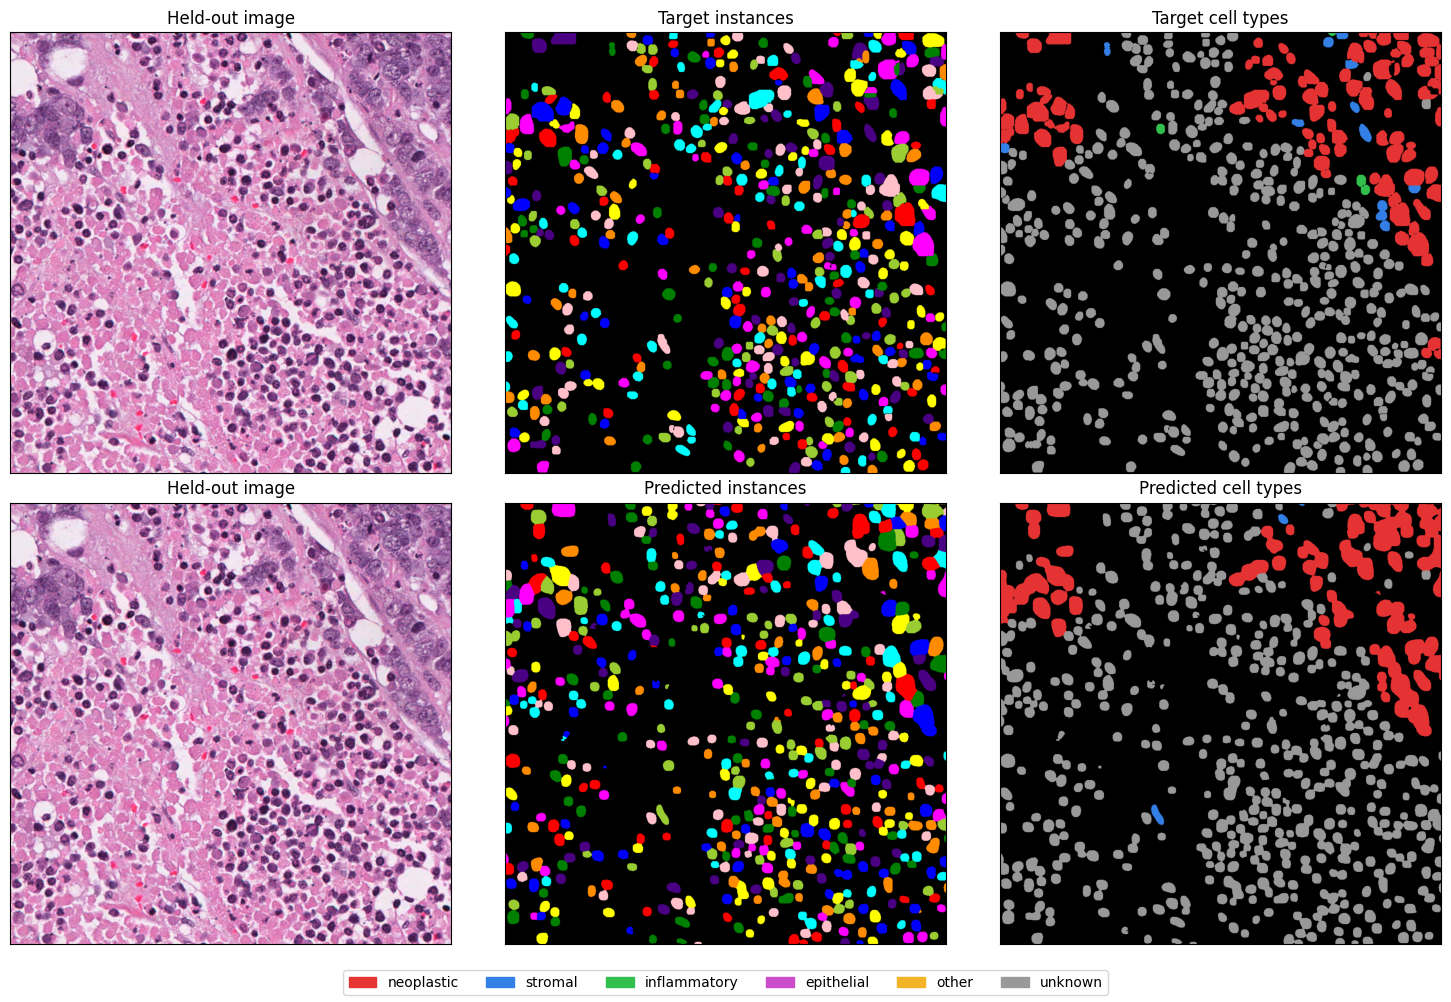

In [6]:
# Compare predictions with the labels for one validation image.
path = evaluation_paths[0]
raw_image = FileHandler.read_img(path)
labels = FileHandler.read_mat(data_root / "validation/regions/labels" / f"{path.stem}.mat")
image = minmax_normalize(raw_image, copy=True)
result = inference_model.post_process(inference_model.predict(image), use_async_postproc=False)
predicted_instances, predicted_classes = result["nuc"][0]

# Fixed colours keep each class identical in target and prediction panels.
class_palette = np.array([
    [0, 0, 0], [0.9, 0.2, 0.2], [0.2, 0.5, 0.9], [0.2, 0.75, 0.3],
    [0.8, 0.3, 0.8], [0.95, 0.7, 0.15], [0.6, 0.6, 0.6],
])
fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes[0, 0].imshow(raw_image)
axes[0, 0].set_title("Held-out image")
axes[0, 1].imshow(label2rgb(labels["inst"], bg_label=0))
axes[0, 1].set_title("Target instances")
axes[0, 2].imshow(class_palette[labels["type"].astype(int)])
axes[0, 2].set_title("Target cell types")
axes[1, 0].imshow(raw_image)
axes[1, 0].set_title("Held-out image")
axes[1, 1].imshow(label2rgb(predicted_instances, bg_label=0))
axes[1, 1].set_title("Predicted instances")
axes[1, 2].imshow(class_palette[predicted_classes])
axes[1, 2].set_title("Predicted cell types")
for axis in axes.flat:
    axis.set(xticks=[], yticks=[])
fig.legend([Patch(color=colour) for colour in class_palette[1:]], class_names[1:],
           loc="lower center", ncol=6)
fig.tight_layout(rect=(0, 0.04, 1, 1))
plt.show()
